# 01 · Exploratory Data Analysis – Arrivo
**Goal:** understand the trips data, clean it, and define the two targets (ETA hours, delayed yes/no).

All logic lives in `src/` (`load.py`, `clean.py`, `eda.py`); this notebook calls it and explains the results.

In [1]:
# Setup: make the project importable from the notebooks/ folder
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
os.environ.setdefault("ARRIVO_OFFLINE", "1")     # use cached/offline enrichment for reproducibility
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)

def show(path, width=11):
    """Display a saved figure inline."""
    img = plt.imread(path); h, w = img.shape[:2]
    fig, ax = plt.subplots(figsize=(width, width * h / w)); ax.imshow(img); ax.axis("off"); plt.show()

## 1. Load the data
`load_canonical()` uses the real Kaggle *Delivery Truck Trips* file if it is in `data/raw/`, otherwise the synthetic dataset with the same column layout. Both are mapped to one canonical schema.

In [2]:
from src.data.load import load_raw, load_canonical
raw, source = load_raw()
print('Source:', source, '| raw shape:', raw.shape)
raw.head(3)

Source: synthetic | raw shape: (15150, 16)


,BookingID,trip_start_date,Planned_ETA,actual_eta,trip_end_date,Origin_Location,Destination_Location,Org_lat_lon,Des_lat_lon,TRANSPORTATION_DISTANCE_IN_KM,vehicleType,Material Shipped,supplierNameCode,ontime,delay,Data_Ping_time
0,ARV100000,2024-03-21 09:10:00,2024-03-22 12:35:42.234443,2024-03-22 19:28:46.221754,2024-03-22 19:28:46.221754,Nagpur,Bhiwandi,"21.15,79.09","19.3,73.06",797.5,24 FT Open Body,Textiles,SUP021,NaN,R,2024-03-22 18:13:46.221754
1,ARV100001,2023-06-08 11:41:00,2023-06-08 18:43:11.573540,2023-06-08 17:41:00.296805,2023-06-08 17:41:00.296805,PUNE,Bhiwandi,"18.52,73.86","19.3,73.06",152.3,17 FT Container,Cement & Steel,SUP010,G,NaN,2023-06-08 16:55:00.296805
2,ARV100002,2024-01-31 23:05:00,2024-02-01 10:02:18.218074,2024-02-01 06:27:50.370713,2024-02-01 06:27:50.370713,Coimbatore,Bengaluru,"11.02,76.96","12.97,77.59",285.4,20 FT Container,FMCG,SUP024,G,NaN,2024-02-01 06:13:50.370713


In [3]:
canonical, _ = load_canonical()
canonical.dtypes.to_frame('dtype').T

,booking_id,dispatch_time,trip_end_time,planned_hours,origin_city,destination_city,origin_lat,origin_lon,dest_lat,dest_lon,road_distance_km,vehicle_type,material_type,supplier_id,origin_region,origin_is_hilly,dest_region,dest_is_hilly
dtype,str,datetime64[us],datetime64[us],float64,str,str,float64,float64,float64,float64,float64,str,str,str,str,int64,str,int64


## 2. Data quality: missing values, duplicates, impossible trips

In [4]:
print('Duplicate booking IDs:', canonical.booking_id.duplicated().sum())
canonical.isna().sum().to_frame('missing').query('missing > 0')

Duplicate booking IDs: 150


,missing
road_distance_km,152
vehicle_type,456
supplier_id,75


In [5]:
from src.data.clean import clean
df, report = clean(canonical)
report

{'rows_in': 15150, 'duplicates_removed': 150, 'missing_timestamps_removed': 0, 'distance_imputed': 150, 'median_detour_factor': 1.203, 'vehicle_type_imputed': 450, 'invalid_trips_removed': 108, 'rows_out': 14892, 'delay_rate': 0.3579}

**Cleaning rules (and why):**
- Duplicates → dropped (same booking sent twice by the GPS provider would double-count).
- Trip speed outside 5–90 km/h, negative or >10-day durations → dropped (these are timestamp errors, not real delays; Indian trucks are speed-governed at 80 km/h).
- Missing distance → haversine × median detour factor (cheap, unbiased estimate).
- Missing vehicle/supplier → `Unknown` category (missingness itself may carry information).

## 3. Targets
- **ETA target** `actual_hours` = trip end − dispatch (hours).
- **Delay target** `is_delayed` = 1 if `actual_hours > planned_hours` (same definition as the Kaggle file's on-time/delay flag).

In [6]:
df[['actual_hours','planned_hours','delay_hours','is_delayed','road_distance_km']].describe().round(2)

,actual_hours,planned_hours,delay_hours,is_delayed,road_distance_km
count,14892.00,14892.00,14892.00,14892.00,14892.00
mean,32.62,33.13,-0.51,0.36,958.29
std,20.92,18.39,7.33,0.48,552.85
min,2.26,4.74,-32.43,0.00,68.70
25%,16.57,18.52,-4.05,0.00,524.90
50%,28.83,29.24,-1.58,0.00,859.30
75%,44.91,46.02,1.80,1.00,1334.20
max,158.49,108.34,81.07,1.00,3167.70


## 4. Plots
Each function in `src/eda.py` saves a PNG to `reports/figures/` (used in the report/slides) and we display it here.

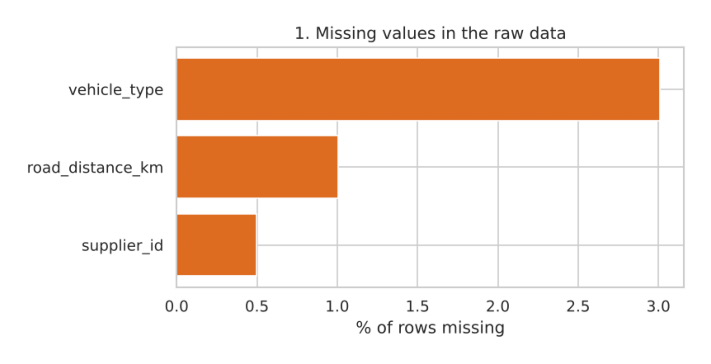

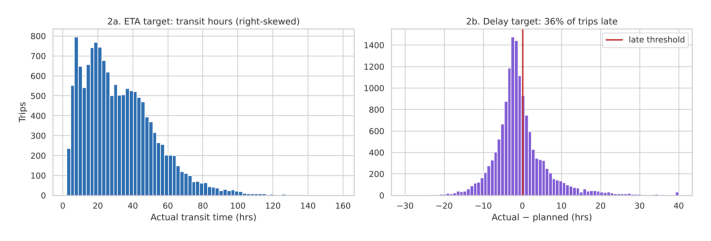

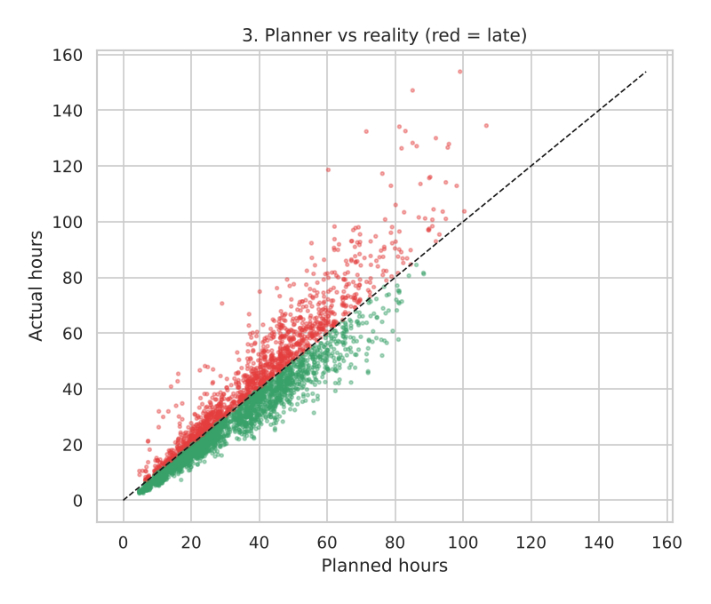

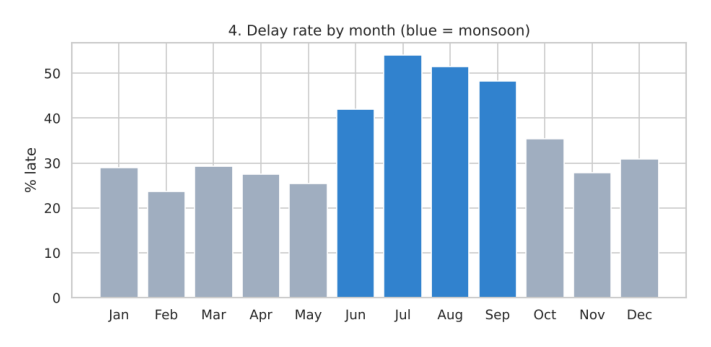

In [7]:
from src.data.enrich import enrich
from src import eda
enriched = enrich(df, live=(source != 'synthetic'))
res = eda.run_all(canonical, df, enriched, report)
for f in sorted((ROOT/'reports/figures').glob('eda_0[1-4]*.png')): show(f, 10)

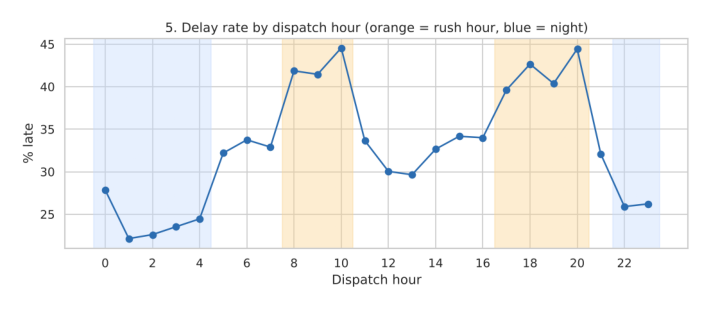

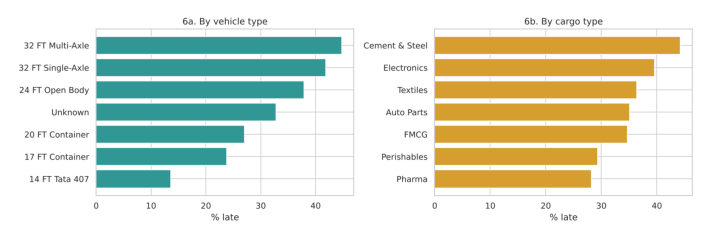

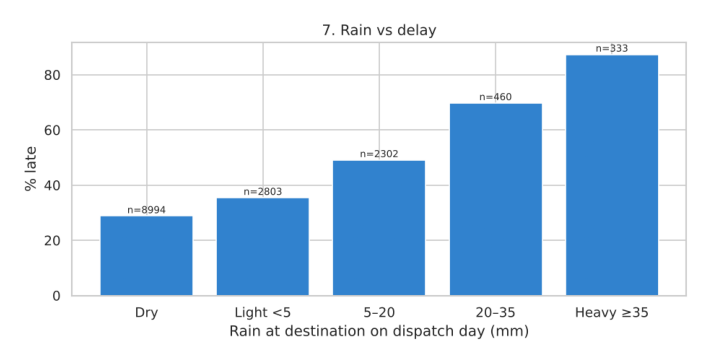

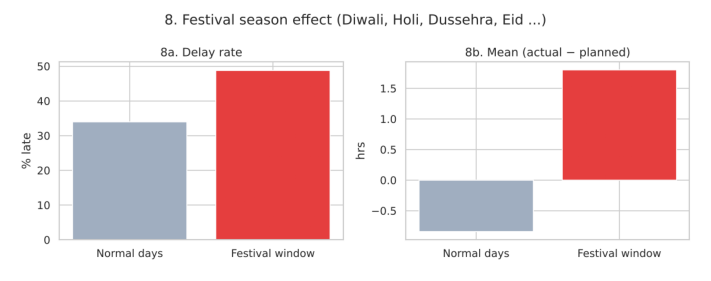

In [8]:
for f in sorted((ROOT/'reports/figures').glob('eda_0[5-8]*.png')): show(f, 10)

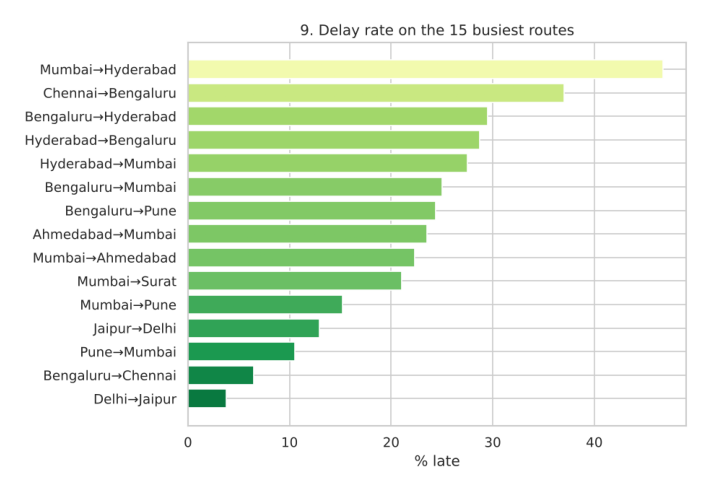

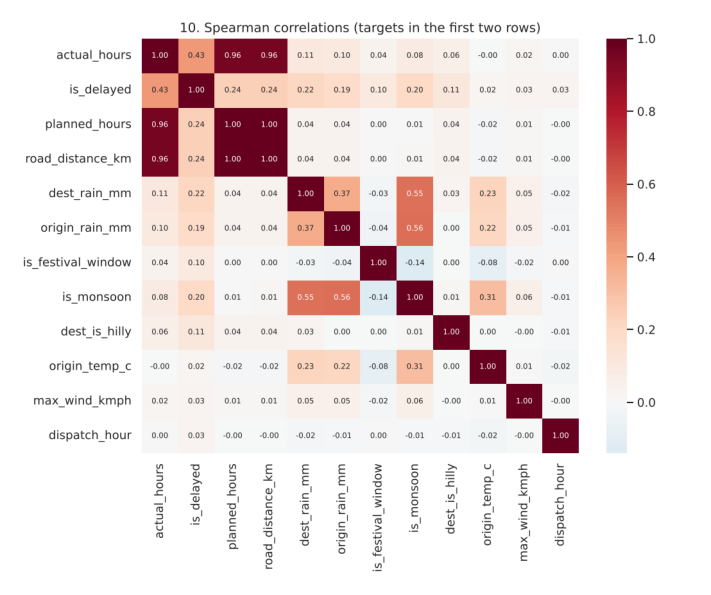

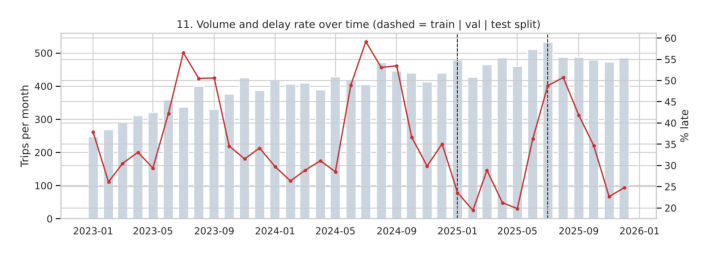

In [9]:
for f in sorted((ROOT/'reports/figures').glob('eda_09*.png')) + sorted((ROOT/'reports/figures').glob('eda_1*.png')): show(f, 10)

## 5. Written insights

In [10]:
print(eda.write_insights(res).read_text())

# EDA insights (auto-generated from the data)

1. **Data quality** – 150 duplicate bookings and 108 impossible trips (negative or >10-day durations, speeds outside 5–90 km/h) were removed; 150 missing distances were estimated from coordinates × median detour factor 1.203; 450 missing vehicle types became 'Unknown'. 14,892 clean trips remain.
2. **Targets** – 35.8% of trips are late (moderate imbalance, ~1 late : 2 on-time). Transit time is right-skewed (skewness 1.06): most trips take 15–45 hrs, a long tail comes from long-haul routes and breakdowns, so MAE is a fairer headline metric than RMSE.
3. **Monsoon** – average delay rate is 49% in Jun–Sep vs 28% in the dry months: the single strongest seasonal signal. Weather features are essential.
4. **Rain at destination** – delay rate rises from 29% on dry days to 87% under heavy rain.
5. **Festivals** – trips dispatched in a festival window are late 49% of the time vs 34% normally, so a custom Indian festival calendar adds signal the pla